In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
VITAL_PERIODIC_DATA_ORIGINAL = "../../data/raw/eicu/vitalPeriodic.csv"
vitalPeriodic_df = pd.read_csv(VITAL_PERIODIC_DATA_ORIGINAL)


In [3]:
print(vitalPeriodic_df.info())
print("Shape: ", vitalPeriodic_df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 1634960 entries, 0 to 1634959
Data columns (total 19 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   vitalperiodicid    1634960 non-null  int64  
 1   patientunitstayid  1634960 non-null  int64  
 2   observationoffset  1634960 non-null  int64  
 3   temperature        112820 non-null   float64
 4   sao2               1441700 non-null  float64
 5   heartrate          1627894 non-null  float64
 6   respiration        1381351 non-null  float64
 7   cvp                202284 non-null   float64
 8   etco2              72780 non-null    float64
 9   systemicsystolic   226475 non-null   float64
 10  systemicdiastolic  226471 non-null   float64
 11  systemicmean       228400 non-null   float64
 12  pasystolic         32083 non-null    float64
 13  padiastolic        32080 non-null    float64
 14  pamean             32632 non-null    float64
 15  st1                613267 non-null   float6

In [4]:
# Đếm số dòng cho TẤT CẢ patientunitstayid
counts = vitalPeriodic_df["patientunitstayid"].value_counts()
print(counts)

patientunitstayid
521456     13150
2416376    12898
343093     11927
1101375    10456
2873230    10088
           ...  
1736752        2
149433         1
600171         1
1617862        1
2787684        1
Name: count, Length: 2375, dtype: int64


In [5]:
 # 1. Xem phân bố thời gian lưu trú của từng patientunitstayid (dùng observationoffset)
stay_duration = vitalPeriodic_df.groupby("patientunitstayid")["observationoffset"].agg(["min", "max"])
stay_duration["duration_hours"] = (stay_duration["max"] - stay_duration["min"]) / 60

# 2. Xem tương quan giữa số dòng và thời gian lưu trú
counts = vitalPeriodic_df["patientunitstayid"].value_counts()
merged = stay_duration.join(counts.rename("record_count"))

# Xem những bệnh nhân có nhiều bản ghi nhất
top_ids = counts.head(5).index
print(merged.loc[top_ids])
bot_ids = counts.tail(5).index
print(merged.loc[bot_ids])
print("so nguoi o ICU >= 4 tieng: ", len(stay_duration[stay_duration["duration_hours"] >= 4]))
print("tong so nguoi o ICU: ", len(stay_duration))

                   min    max  duration_hours  record_count
patientunitstayid                                          
521456               8  66473     1107.750000         13150
2416376              7  65577     1092.833333         12898
343093               7  60312     1005.083333         11927
1101375             48  53183      885.583333         10456
2873230              7  51582      859.583333         10088
                    min   max  duration_hours  record_count
patientunitstayid                                          
1736752            2467  2672        3.416667             2
149433                5     5        0.000000             1
600171                6     6        0.000000             1
1617862             242   242        0.000000             1
2787684               5     5        0.000000             1
so nguoi o ICU >= 4 tieng:  2252
tong so nguoi o ICU:  2375


In [6]:
print(stay_duration.info())

<class 'pandas.DataFrame'>
Index: 2375 entries, 141764 to 3353113
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   min             2375 non-null   int64  
 1   max             2375 non-null   int64  
 2   duration_hours  2375 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 138.8 KB
None


In [7]:
display(vitalPeriodic_df.head(10))

,vitalperiodicid,patientunitstayid,observationoffset,temperature,sao2,heartrate,respiration,cvp,etco2,systemicsystolic,systemicdiastolic,systemicmean,pasystolic,padiastolic,pamean,st1,st2,st3,icp
0,29524122,141765,1179,NaN,NaN,82.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,29557845,141765,189,NaN,97.0,76.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,29524442,141765,1169,NaN,NaN,84.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,29513052,141765,1534,NaN,NaN,92.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,29524600,141765,1164,NaN,NaN,86.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,29558795,141765,159,NaN,96.0,80.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,29511454,141765,1584,NaN,NaN,94.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,29553160,141765,334,NaN,96.0,76.0,29.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,29485816,141764,74,NaN,NaN,126.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-1.7,-1.7,NaN
9,29476745,141764,344,NaN,NaN,104.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1,-0.7,-0.7,NaN


In [8]:
print(vitalPeriodic_df["patientunitstayid"].nunique())
print(vitalPeriodic_df["patientunitstayid"].value_counts())

2375
patientunitstayid
521456     13150
2416376    12898
343093     11927
1101375    10456
2873230    10088
           ...  
1736752        2
149433         1
600171         1
1617862        1
2787684        1
Name: count, Length: 2375, dtype: int64


In [9]:
vitalPeriodic_df_24h = vitalPeriodic_df[
    (vitalPeriodic_df["observationoffset"] >= 0) & (vitalPeriodic_df["observationoffset"] <= 1440)]

In [10]:
vitalPeriodic_df_24h.describe()

,vitalperiodicid,patientunitstayid,observationoffset,temperature,sao2,heartrate,respiration,cvp,etco2,systemicsystolic,systemicdiastolic,systemicmean,pasystolic,padiastolic,pamean,st1,st2,st3,icp
count,5.538460e+05,5.538460e+05,553846.000000,29874.000000,488056.000000,551056.000000,486571.000000,48801.000000,15303.000000,75756.000000,75754.000000,76400.000000,17413.000000,17411.000000,17627.000000,224192.000000,241184.00000,214379.000000,1590.000000
mean,1.071080e+09,1.759499e+06,680.520098,39.058584,96.495037,84.349554,19.504786,32.504621,26.237797,120.399071,59.171186,79.764699,34.427612,17.457010,24.147841,1.433707,2.83654,3.043979,7.340881
std,6.689437e+08,1.007290e+06,405.524965,10.872285,5.001862,18.996591,6.530600,75.104926,13.392947,24.262010,16.320534,20.195172,11.733408,7.697492,10.040638,15.083966,25.55396,30.151879,6.573554
min,1.379700e+05,1.417640e+05,0.000000,0.500000,0.000000,0.000000,0.000000,-50.000000,0.000000,-44.000000,-76.000000,-45.000000,3.000000,-2.000000,-2.000000,-9.700000,-11.90000,-12.600000,-18.000000
25%,4.768174e+08,9.263170e+05,330.000000,36.700000,95.000000,70.000000,16.000000,7.000000,21.000000,105.000000,50.000000,68.000000,27.000000,12.000000,18.000000,-0.160000,-0.30000,-0.200000,3.000000
50%,1.108702e+09,1.714511e+06,660.000000,37.200000,97.000000,83.000000,19.000000,11.000000,28.000000,119.000000,58.000000,77.000000,33.000000,17.000000,23.000000,0.000000,0.00000,0.000000,8.000000
75%,1.665160e+09,2.735662e+06,1020.000000,37.800000,99.000000,96.000000,23.000000,16.000000,36.000000,135.000000,66.000000,88.000000,40.000000,22.000000,29.000000,0.160000,0.30000,0.200000,12.000000
max,2.188285e+09,3.353113e+06,1440.000000,102.400000,100.000000,202.000000,163.000000,400.000000,80.000000,349.000000,344.000000,346.000000,291.000000,291.000000,309.000000,520.000000,1190.00000,1200.000000,78.000000


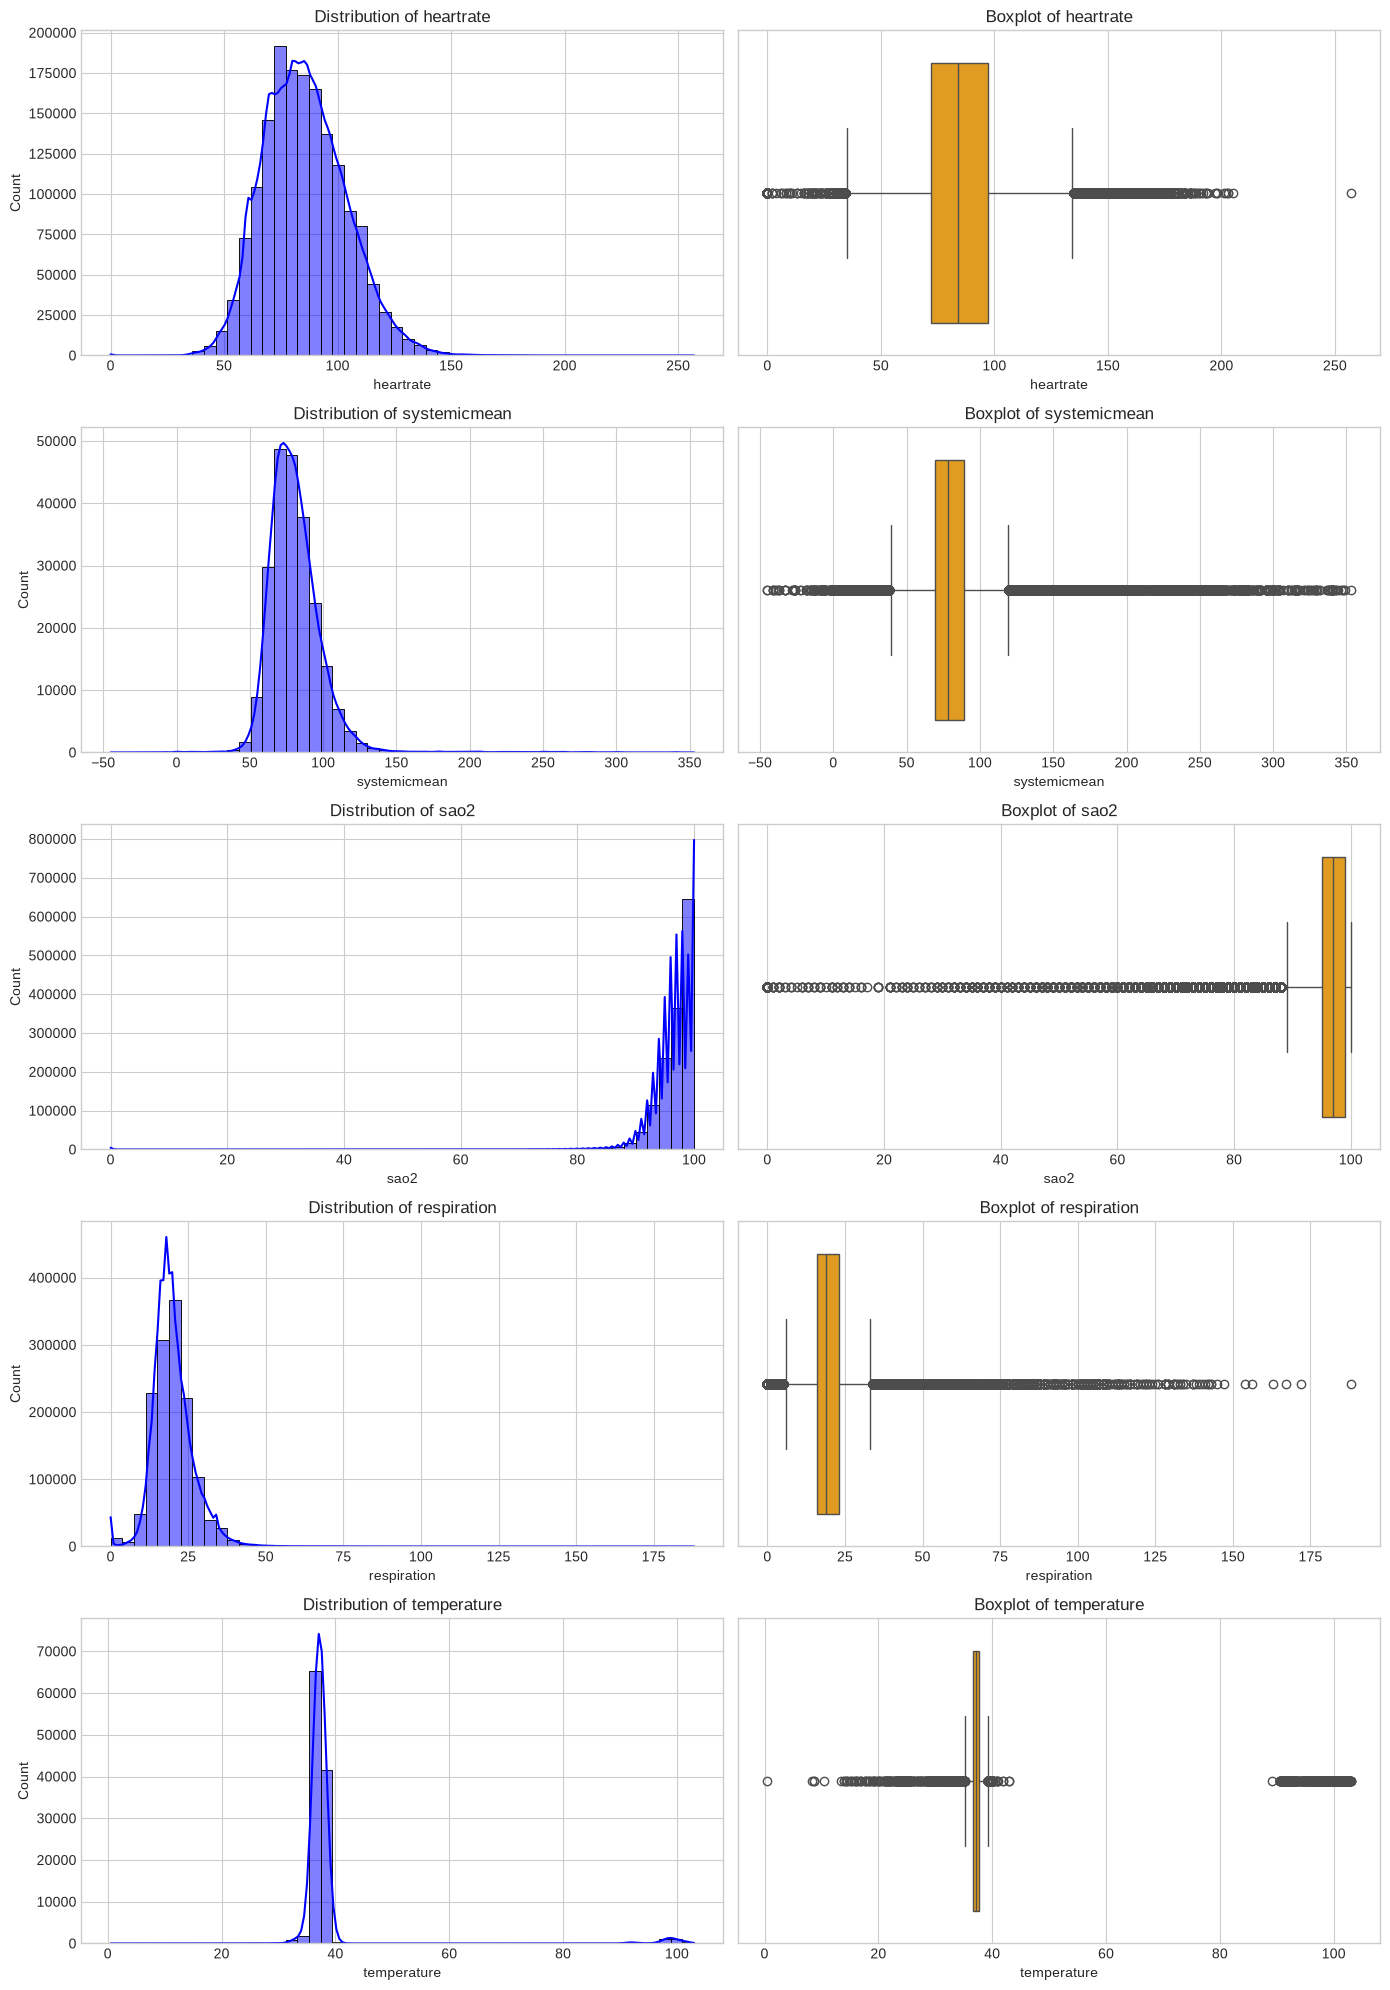

In [11]:
# Danh sách các cột sinh hiệu cần khảo sát
vitals = ["heartrate", "systemicmean", "sao2", "respiration", "temperature"]

# Thiết lập giao diện
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(len(vitals), 2, figsize=(14, 4 * len(vitals)))

for i, col in enumerate(vitals):
    # Lọc bỏ giá trị NaN trước khi vẽ để tránh lỗi
    data = vitalPeriodic_df[col].dropna()

    # 1. Biểu đồ Histogram + KDE (bên trái)
    sns.histplot(data, ax=axes[i, 0], kde=True, color="blue", bins=50)
    axes[i, 0].set_title(f"Distribution of {col}")
    axes[i, 0].set_xlabel(col)

    # 2. Biểu đồ Boxplot (bên phải) để nhìn rõ các điểm outlier
    sns.boxplot(x=data, ax=axes[i, 1], color="orange")
    axes[i, 1].set_title(f"Boxplot of {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

In [12]:
# Đếm số dòng có systemicmean < 20
invalid_count = (vitalPeriodic_df["systemicmean"] < 20).sum()
total_count = vitalPeriodic_df["systemicmean"].notna().sum()

# Tính tỷ lệ %
percentage = (invalid_count / total_count) * 100
print(f"Số lượng giá trị bất thường: {invalid_count:,} ({percentage:.2f}%)")

Số lượng giá trị bất thường: 302 (0.13%)


In [14]:
print(len(vitalPeriodic_df_24h[vitalPeriodic_df_24h["sao2"]<=0]))

684


In [15]:
print(vitalPeriodic_df_24h[vitalPeriodic_df_24h["sao2"]<=0].info())
print(vitalPeriodic_df_24h[vitalPeriodic_df_24h["sao2"]<=0].describe())

<class 'pandas.DataFrame'>
Index: 684 entries, 180764 to 1557116
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   vitalperiodicid    684 non-null    int64  
 1   patientunitstayid  684 non-null    int64  
 2   observationoffset  684 non-null    int64  
 3   temperature        0 non-null      float64
 4   sao2               684 non-null    float64
 5   heartrate          684 non-null    float64
 6   respiration        684 non-null    float64
 7   cvp                2 non-null      float64
 8   etco2              294 non-null    float64
 9   systemicsystolic   0 non-null      float64
 10  systemicdiastolic  0 non-null      float64
 11  systemicmean       0 non-null      float64
 12  pasystolic         0 non-null      float64
 13  padiastolic        0 non-null      float64
 14  pamean             0 non-null      float64
 15  st1                9 non-null      float64
 16  st2                9 non-null    